# The Channelized Egg model for rebuttle
- analyze the influence of monitoring wells
- analyze the influence of noise levels, especially high noise levels, check if generation perfectly match the noisy data
- prove the model can generate longer trajectories: train on short, generation on long
- in this case, may select one well-inversed scenario to show the posterior diversity

In [ ]:
%env CUDA_VISIBLE_DEVICES = 1

import torch
import numpy as np
import h5py
import matplotlib.pyplot as plt
import seaborn as sns

from functools import partial
import sys
sys.path.append("../../..")
from ConditionalDiffusionGeneration.src.guided_diffusion.unet import create_model
from ConditionalDiffusionGeneration.src.guided_diffusion.condition_methods import get_conditioning_method
from ConditionalDiffusionGeneration.src.guided_diffusion.measurements import get_noise, get_operator
from ConditionalDiffusionGeneration.src.guided_diffusion.gaussian_diffusion import create_sampler
from einops import rearrange

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda")

# define my own color
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import json
with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]
rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)
x = rgb_points[:, 0]
r = rgb_points[:, 1]
g = rgb_points[:, 2]
b = rgb_points[:, 3]
b = rgb_points[:, 3]
colors = list(zip(x, zip(r, g, b)))
mycmap = LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)

shale_color    = "#4c72b0"
sand_color     = "#f4a522"
binarycm = ListedColormap([shale_color, sand_color])

egg_coordinates = np.load("../../../Dataset/egg_coordinates.npy")
print(f"Egg coordinates shape: {egg_coordinates.shape}")
import meshio
VTU = "../../../Dataset/egg_model_1layer.vtu"
mesh = meshio.read(VTU)
print(mesh)

# use these indices to find the corresponding coordinates in egg_coordinates
well_4_idx = [2432, 332, 557, 1979]
well_8_idx = [2432, 332, 557, 1979, 1987, 1688, 1160, 479]
well_obs = [1987, 1688, 1160, 479]
well_12_idx = [2432, 332, 557, 1979, 1987, 1688, 1160, 479, 2272, 1411, 461, 1238]
print(len(well_4_idx), len(well_8_idx), len(well_12_idx))


env: CUDA_VISIBLE_DEVICES=1
Egg coordinates shape: (2491, 2)
<meshio mesh object>
  Number of points: 7442
  Number of cells:
    hexahedron: 2491
  Cell data: I_index, J_index, flat_index
4 8 12


# *Pre determine the points / coordinates / indexes in this Egg model*

In [5]:
def active_to_grid(
    values: np.ndarray,
    flat_index: np.ndarray,
    nx: int = 60,
    ny: int = 60,
    fill_value: float = np.nan,
) -> np.ma.MaskedArray:

    assert len(values) == len(flat_index), (
        f"Length of values {len(values)} does not match length of flat_index {len(flat_index)}"
    )
    grid = np.full(ny * nx, fill_value, dtype=float)
    grid[flat_index] = values
    grid2d = grid.reshape(ny, nx)

    # mask = True where inactive (no data written)
    mask = np.ones((ny, nx), dtype=bool)
    rows, cols = np.unravel_index(flat_index, (ny, nx))  # get row, col indices of active cells
    mask[rows, cols] = False

    return np.ma.array(grid2d, mask=mask)

def plot_on_mesh(
    values: np.ndarray,
    vtu_path: str        = "../../../Dataset/egg_model_1layer.vtu",
    ax: plt.Axes         = None,
    cmap: plt.Colormap     = None,
    **kwargs
) -> plt.Axes:
    values = values.numpy() if isinstance(values, torch.Tensor) else values
    mesh     = meshio.read(vtu_path)
    flat_idx = mesh.cell_data["flat_index"][0]

    grid = active_to_grid(values, flat_idx)
    cmap.set_bad(color=(0, 0, 0, 0))  # set masked (inactive) values to transparent

    if ax is None:
        print("Creating new figure and axes")
        fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(grid, origin="lower", cmap=cmap, **kwargs)
    ax.set_facecolor((0, 0, 0, 0))
    ax.set_axis_off()
    return ax

def find_well_coords(well_idx, egg_coordinates):
    well_coords = egg_coordinates[well_idx]
    return well_coords

def mark_wells(ax, well_indices, flat_index_path="../../../Dataset/egg_model_1layer.vtu", 
               nx=60, ny=60, color='red', s=80, **kwargs):
    mesh = meshio.read(flat_index_path)
    flat_idx = mesh.cell_data["flat_index"][0]
    
    rows, cols = np.unravel_index(flat_idx, (ny, nx))
    
    for wi in well_indices:
        ax.scatter(cols[wi], rows[wi], marker='^', c=color, s=s, 
                   edgecolors='none', zorder=100, **kwargs)


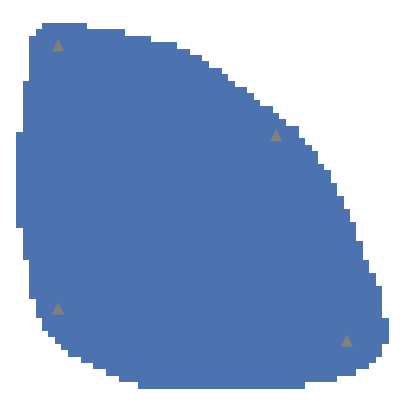

In [40]:
fig2, ax2 = plt.subplots(figsize=(5, 5))
ax = plot_on_mesh(np.ones(2491,), VTU, ax=ax2, cmap=binarycm)
mark_wells(ax, well_4_idx, VTU, color='gray')

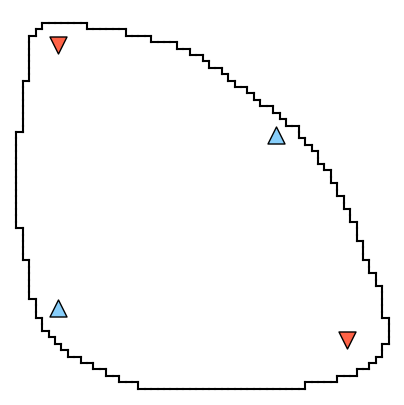

In [402]:
def plot_on_mesh_with_outline(
    values: np.ndarray,
    vtu_path: str = "../../../Dataset/egg_model_1layer.vtu",
    nx: int = 60, ny: int = 60,
    ax: plt.Axes = None,
    well_indices: list = None,
    well_color: str = "red",
    outline: bool = True,
    colorbar: bool = False,
    label: str = "",
) -> plt.Axes:
    from matplotlib.colors import ListedColormap
    transparent_cmap = ListedColormap([(0, 0, 0, 0)])
    
    mesh = meshio.read(vtu_path)
    flat_idx = mesh.cell_data["flat_index"][0]

    grid = active_to_grid(values, flat_idx, nx, ny)

    transparent_cmap.set_bad(color=(0, 0, 0, 0))

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))

    im = ax.imshow(grid, cmap=transparent_cmap, origin="lower")

    if outline:
        active = (~grid.mask).astype(int)
        h_edges = np.diff(active, axis=0)
        for i, j in zip(*np.where(h_edges != 0)):
            ax.plot([j-0.5, j+0.5], [i+0.5, i+0.5], 'k-', lw=1.5)
        v_edges = np.diff(active, axis=1)
        for i, j in zip(*np.where(v_edges != 0)):
            ax.plot([j+0.5, j+0.5], [i-0.5, i+0.5], 'k-', lw=1.5)
        for j in np.where(active[0, :])[0]:
            ax.plot([j-0.5, j+0.5], [-0.5, -0.5], 'k-', lw=1.5)
        for j in np.where(active[-1, :])[0]:
            ax.plot([j-0.5, j+0.5], [ny-0.5, ny-0.5], 'k-', lw=1.5)
        for i in np.where(active[:, 0])[0]:
            ax.plot([-0.5, -0.5], [i-0.5, i+0.5], 'k-', lw=1.5)
        for i in np.where(active[:, -1])[0]:
            ax.plot([nx-0.5, nx-0.5], [i-0.5, i+0.5], 'k-', lw=1.5)

    if well_indices is not None:
        rows, cols = np.unravel_index(flat_idx, (ny, nx))
        # for wi in well_indices:
        #     ax.scatter(cols[wi], rows[wi], marker='^', c=well_color, s=150,
        #                edgecolors='k', zorder=100)
        for wi in [2432, 332]: # injection wells
            ax.scatter(cols[wi], rows[wi], marker='v', c='tomato', s=150,
                       edgecolors='k', zorder=100)
        for wi in [557, 1979]: # production wells
            ax.scatter(cols[wi], rows[wi], marker='^', c='lightskyblue', s=150,
                       edgecolors='k', zorder=100)

    if colorbar:
        ax.get_figure().colorbar(im, ax=ax, shrink=0.7, label=label)

    ax.set_facecolor("white")
    ax.set_axis_off()
    return ax

ax = plot_on_mesh_with_outline(np.zeros(2491,), VTU, well_indices=well_8_idx, well_color='lightgray')
plt.savefig("Egg_outputs/figs/WELL-CONFIG-inj-prod.pdf", bbox_inches='tight', pad_inches=0)

# **analysis**

In [3]:
gt = torch.from_numpy(np.load('../../../Dataset/Egg2d_channelized_all3.npy')[1922]).cpu()
plume = torch.load("Egg_outputs/pts/CNF_out_5%noisy_plume.pt", map_location="cpu")
plume10 = torch.load("Egg_outputs/pts/CNF_out_10%noisy_plume.pt", map_location="cpu")
plume20 = torch.load("Egg_outputs/pts/CNF_out_20%noisy_plume.pt", map_location="cpu")
well_8 = torch.load("Egg_outputs/pts/CNF_out_8.pt", map_location="cpu")
uncond = torch.load("Egg_outputs/pts/CNF_out_uncond.pt", map_location="cpu")


def clamp_sat(input):
    input[..., 1][input[..., 1] < 0.08] = 0
    input[..., -1][input[..., -1] <= 800] = 10
    input[..., -1][input[..., -1] > 800] = 1500
    return input
plume = clamp_sat(plume)
well_8 = clamp_sat(well_8)
uncond = clamp_sat(uncond)
plume10 = clamp_sat(plume10)
plume20 = clamp_sat(plume20)
print(f"GT shape: {gt.shape}, Plume shape: {plume.shape}, Well 8 shape: {well_8.shape}, Uncond shape: {uncond.shape}")

GT shape: torch.Size([192, 2491, 3]), Plume shape: torch.Size([10, 192, 2491, 3]), Well 8 shape: torch.Size([10, 192, 2491, 3]), Uncond shape: torch.Size([50, 192, 2491, 3])


In [255]:
k = uncond[..., -1].mean(dim=1)
k[k < 800] = 10
k[k >= 800] = 1500
print(k.shape, k.unique())
np.save("Egg_outputs/pts/uncond_permeability.npy", k.cpu().numpy())

torch.Size([50, 2491]) tensor([  10., 1500.])


Creating new figure and axes


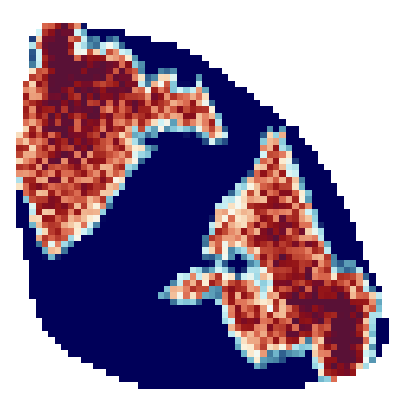

In [405]:
plot_on_mesh(gt[-1,..., 1] + gt[-1,..., 1].ne(0) * torch.rand_like(gt[-1,..., 1]) * 0.2, VTU, cmap=mycmap, vmin=0, vmax=0.6)
plt.savefig("Egg_outputs/figs/NOISE-CONDITION-plume20%.pdf", bbox_inches='tight', pad_inches=0)

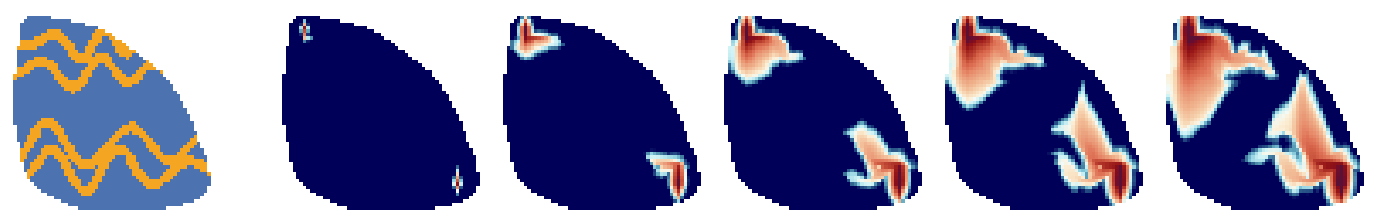

In [44]:
def make_gt_1x3(figsize=(18, 3), width_space=0.25, height_space=0.0):
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=figsize, constrained_layout=False)

    gs = gridspec.GridSpec(1, 7, width_ratios=[1, 0.15, 1, 1, 1, 1, 1], wspace=width_space, hspace=height_space)

    axes = []

    ax = fig.add_subplot(gs[0])
    ax.set_aspect('equal')
    ax.axis('off')
    axes.append(ax)
    for col in range(2, 7):
        ax = fig.add_subplot(gs[col])
        ax.set_aspect('equal')
        ax.axis('off')
        axes.append(ax)
    
    return fig, axes

def make_gt_1x6_contour(gt_tensor, figsize=(18, 3), width_space=0.25, height_space=0.0):
    fig, axes = make_gt_1x3(figsize=figsize, width_space=width_space, height_space=height_space)

    # physics time is: [1a, 10a, 25a, 40a, 60a]
    ts = [3, 31, 79, 129, 191]
    # ts = [3, 31, 60, 70, 120]

    plot_on_mesh(gt_tensor[:, ..., -1].mean(dim=0), VTU, ax=axes[0], cmap=binarycm, vmin=10, vmax=1500)

    for i, ts in enumerate(ts):
        plot_on_mesh(gt_tensor[ts, :, 1], VTU, ax=axes[i+1], vmin=0, vmax=0.6, cmap=mycmap)
    
    return fig, axes

gt = torch.from_numpy(np.load('../../../Dataset/Egg2d_channelized_all3.npy')[1922]).cpu()
fig, axes = make_gt_1x6_contour(gt, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
plt.savefig("Egg_outputs/figs/gt_contour.pdf", bbox_inches='tight')

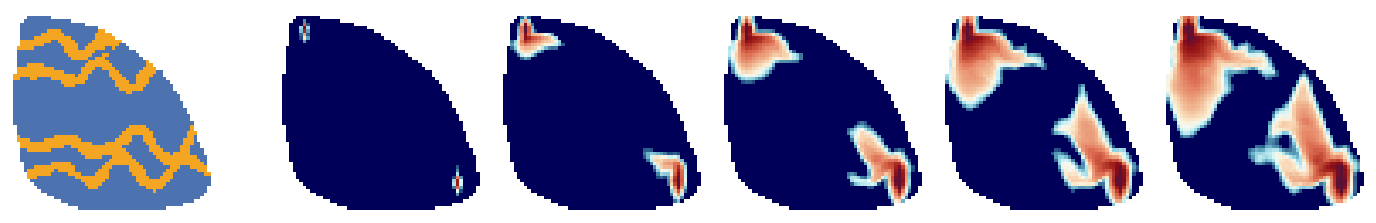

In [46]:
def make_gene_1x6_contour(gene_tensor, show_idx=0, figsize=(18, 3), width_space=0.25, height_space=0.0):
    fig, axes = make_gt_1x3(figsize=figsize, width_space=width_space, height_space=height_space)
    
    # physics time is: [1a, 10a, 25a, 40a, 60a]
    ts = [3, 31, 79, 129, 191]
    # ts = [3, 31, 60, 70, 120]

    plot_on_mesh(gene_tensor[show_idx, :, ..., -1].mean(dim=0), VTU, ax=axes[0], cmap=binarycm, vmin=10, vmax=1500)

    for i, ts in enumerate(ts):
        plot_on_mesh(gene_tensor[show_idx, ts, :, 1], VTU, ax=axes[i+1], vmin=0, vmax=0.6, cmap=mycmap)
    
    return fig, axes

fig, axes = make_gene_1x6_contour(plume, show_idx=1, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
plt.savefig("Egg_outputs/figs/gene_5%noisy_plume_contour.pdf", bbox_inches='tight')

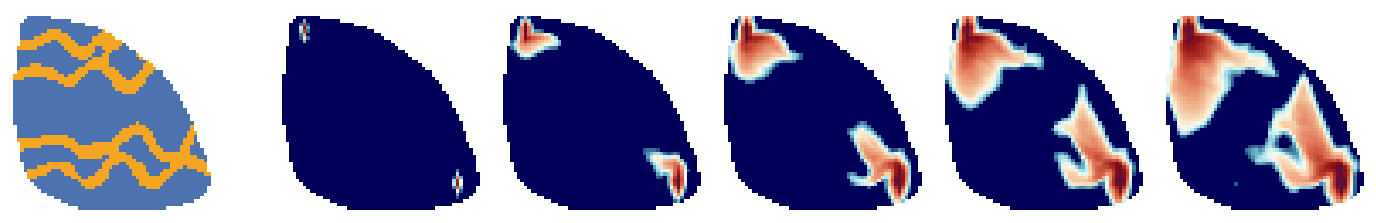

In [58]:
fig, axes = make_gene_1x6_contour(plume10, show_idx=1, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
plt.savefig("Egg_outputs/figs/gene_10%noisy_plume_contour.pdf", bbox_inches='tight')

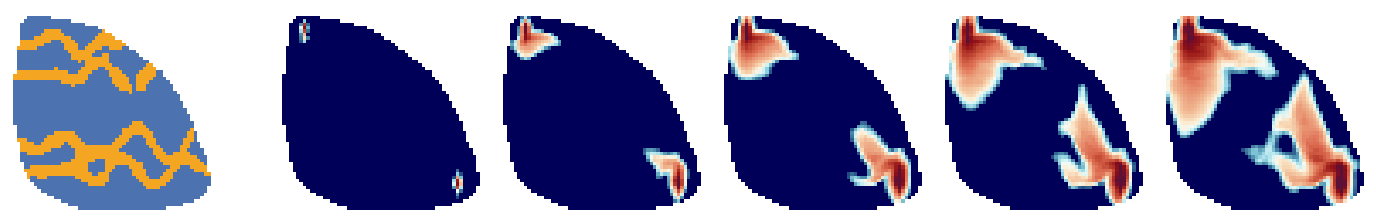

In [415]:
fig, axes = make_gene_1x6_contour(plume20, show_idx=1, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
plt.savefig("Egg_outputs/figs/gene_20%noisy_plume_contour.pdf", bbox_inches='tight')

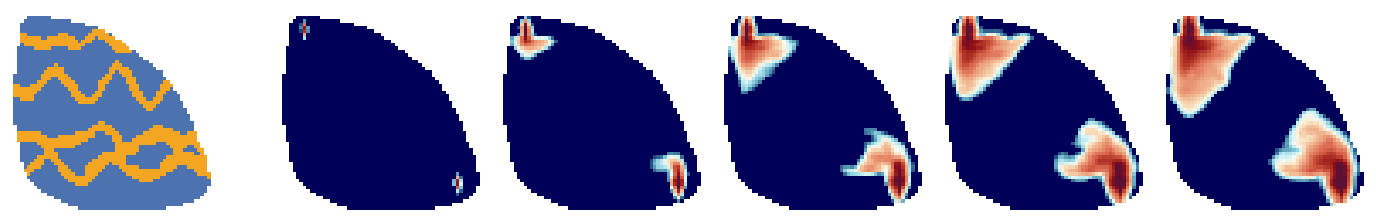

In [262]:
fig, axes = make_gene_1x6_contour(well_8, show_idx=9, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
plt.savefig("Egg_outputs/figs/gene_well8_contour.pdf", bbox_inches='tight')

In [2]:
from matplotlib.ticker import FuncFormatter
from scipy.ndimage import label

def two_point_cluster_function_masked(masked_field, max_lag=25, connectivity=8):
    """
    S2 is two point probability,
    C2 is two point cluster function (same cluster probability)
    """
    valid_mask = ~masked_field.mask
    field = (masked_field.data > 800).astype(int)
    field[~valid_mask] = 0

    if connectivity == 8:
        structure = np.ones((3, 3))
    else:
        structure = np.array([[0,1,0],[1,1,1],[0,1,0]])

    labeled, _ = label(field, structure=structure)
    
    ny, nx = field.shape
    lags = np.arange(0, max_lag + 1)
    C2 = np.zeros(len(lags))
    S2 = np.zeros(len(lags))
    counts = np.zeros(len(lags))
    
    dy = 0
    for dx in range(0, max_lag + 1):
        x1s, x1e = 0, nx - dx
        if x1e <= x1s:
            continue

        m1 = valid_mask[:, x1s:x1e]
        m2 = valid_mask[:, x1s+dx:x1e+dx]
        valid = m1 & m2

        n_valid = np.sum(valid)
        if n_valid == 0:
            continue

        f1 = field[:, x1s:x1e]
        f2 = field[:, x1s+dx:x1e+dx]
        l1 = labeled[:, x1s:x1e]
        l2 = labeled[:, x1s+dx:x1e+dx]

        S2[dx] += np.sum((f1 * f2) * valid)
        C2[dx] += np.sum((l1 == l2) & (l1 > 0) & valid)
        counts[dx] += n_valid

    nonzero = counts > 0
    C2[nonzero] /= counts[nonzero]
    S2[nonzero] /= counts[nonzero]

    return lags, C2, S2, counts

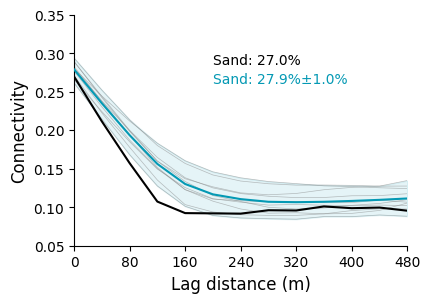

In [109]:
masked_grid = active_to_grid(gt[:, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan)
gene = [active_to_grid(plume[i, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan) for i in range(plume.shape[0])]

lags, C2, S2, counts = two_point_cluster_function_masked(
    masked_grid, max_lag=12, connectivity=8
)

results_gene = [
    two_point_cluster_function_masked(g, max_lag=12, connectivity=8)
    for g in gene
]

fig, ax = plt.subplots(1, 1, figsize=(4.3, 3))

ax.plot(lags, C2, 'k', lw=1.5, zorder=100)
mean_c2 = []
for i in range(len(gene)):
    lags_g, C2_g, S2_g, counts_g = results_gene[i]
    ax.plot(lags_g, C2_g, 'gray', lw=0.5, alpha=0.5, zorder=1)
    mean_c2.append(C2_g)
ax.plot(lags, np.mean(mean_c2, axis=0), '#0499b4', lw=1.5, zorder=101)
ax.fill_between(lags, np.min(mean_c2, axis=0), np.max(mean_c2, axis=0), color='#0499b4', alpha=0.1, zorder=0)

ax.set_xlabel('Lag distance (m)', fontsize=12)
ax.set_ylabel('Connectivity', fontsize=12)
ax.set_ylim(0.05, 0.35)
ax.set_xlim(0, 12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*40:.0f}'))

gt_ratio= (gt[:, ..., -1].mean(dim=0) == 1500).float().mean().item()
gene_ratios = [(plume[i, ..., -1].mean(dim=0) >= 800).float().mean().item() for i in range(plume.shape[0])]
ax.text(5, 0.3, f'Sand: {gt_ratio:.1%}', fontsize=10, ha='left', va='top')
ax.text(5, 0.275, f'Sand: {np.mean(gene_ratios):.1%}±{np.std(gene_ratios):.1%}', fontsize=10, ha='left', va='top', color='#0499b4')

plt.savefig("Egg_outputs/figs/K_connectivity_plume5%.pdf", bbox_inches='tight')
plt.show()

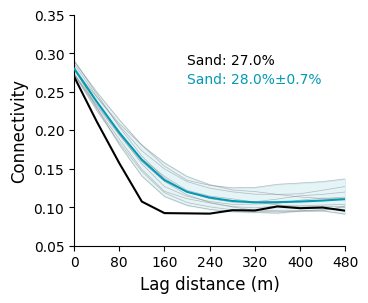

In [67]:
masked_grid = active_to_grid(gt[:, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan)
gene = [active_to_grid(plume10[i, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan) for i in range(plume.shape[0])]

lags, C2, S2, counts = two_point_cluster_function_masked(
    masked_grid, max_lag=12, connectivity=8
)

results_gene = [
    two_point_cluster_function_masked(g, max_lag=12, connectivity=8)
    for g in gene
]

fig, ax = plt.subplots(1, 1, figsize=(3.5, 3))

ax.plot(lags, C2, 'k', lw=1.5, zorder=100)
mean_c2 = []
for i in range(len(gene)):
    lags_g, C2_g, S2_g, counts_g = results_gene[i]
    ax.plot(lags_g, C2_g, 'gray', lw=0.5, alpha=0.5, zorder=1)
    mean_c2.append(C2_g)
ax.plot(lags, np.mean(mean_c2, axis=0), '#0499b4', lw=1.5, zorder=101)
ax.fill_between(lags, np.min(mean_c2, axis=0), np.max(mean_c2, axis=0), color='#0499b4', alpha=0.1, zorder=0)

ax.set_xlabel('Lag distance (m)', fontsize=12)
ax.set_ylabel('Connectivity', fontsize=12)
ax.set_ylim(0.05, 0.35)
ax.set_xlim(0, 12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*40:.0f}'))

gt_ratio= (gt[:, ..., -1].mean(dim=0) == 1500).float().mean().item()
gene_ratios = [(plume10[i, ..., -1].mean(dim=0) >= 800).float().mean().item() for i in range(plume.shape[0])]
ax.text(5, 0.3, f'Sand: {gt_ratio:.1%}', fontsize=10, ha='left', va='top')
ax.text(5, 0.275, f'Sand: {np.mean(gene_ratios):.1%}±{np.std(gene_ratios):.1%}', fontsize=10, ha='left', va='top', color='#0499b4')


plt.savefig("Egg_outputs/figs/K_connectivity_plume10%.pdf", bbox_inches='tight')
plt.show()

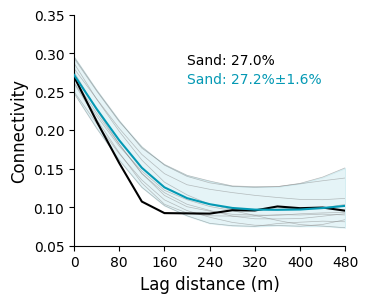

In [68]:
masked_grid = active_to_grid(gt[:, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan)
gene = [active_to_grid(plume20[i, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan) for i in range(plume.shape[0])]

lags, C2, S2, counts = two_point_cluster_function_masked(
    masked_grid, max_lag=12, connectivity=8
)

results_gene = [
    two_point_cluster_function_masked(g, max_lag=12, connectivity=8)
    for g in gene
]

fig, ax = plt.subplots(1, 1, figsize=(3.5, 3))

ax.plot(lags, C2, 'k', lw=1.5, zorder=100)
mean_c2 = []
for i in range(len(gene)):
    lags_g, C2_g, S2_g, counts_g = results_gene[i]
    ax.plot(lags_g, C2_g, 'gray', lw=0.5, alpha=0.5, zorder=1)
    mean_c2.append(C2_g)
ax.plot(lags, np.mean(mean_c2, axis=0), '#0499b4', lw=1.5, zorder=101)
ax.fill_between(lags, np.min(mean_c2, axis=0), np.max(mean_c2, axis=0), color='#0499b4', alpha=0.1, zorder=0)

ax.set_xlabel('Lag distance (m)', fontsize=12)
ax.set_ylabel('Connectivity', fontsize=12)
ax.set_ylim(0.05, 0.35)
ax.set_xlim(0, 12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*40:.0f}'))

gt_ratio= (gt[:, ..., -1].mean(dim=0) == 1500).float().mean().item()
gene_ratios = [(plume20[i, ..., -1].mean(dim=0) >= 800).float().mean().item() for i in range(plume20.shape[0])]
ax.text(5, 0.3, f'Sand: {gt_ratio:.1%}', fontsize=10, ha='left', va='top')
ax.text(5, 0.275, f'Sand: {np.mean(gene_ratios):.1%}±{np.std(gene_ratios):.1%}', fontsize=10, ha='left', va='top', color='#0499b4')

plt.savefig("Egg_outputs/figs/K_connectivity_plume20%.pdf", bbox_inches='tight')
plt.show()

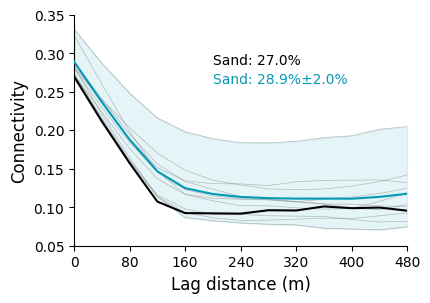

In [110]:
masked_grid = active_to_grid(gt[:, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan)
gene = [active_to_grid(well_8[i, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan) for i in range(well_8.shape[0])]

lags, C2, S2, counts = two_point_cluster_function_masked(
    masked_grid, max_lag=12, connectivity=8
)

results_gene = [
    two_point_cluster_function_masked(g, max_lag=12, connectivity=8)
    for g in gene
]

fig, ax = plt.subplots(1, 1, figsize=(4.3, 3))

ax.plot(lags, C2, 'k', lw=1.5, zorder=100)
mean_c2 = []
for i in range(len(gene)):
    lags_g, C2_g, S2_g, counts_g = results_gene[i]
    ax.plot(lags_g, C2_g, 'gray', lw=0.5, alpha=0.5, zorder=1)
    mean_c2.append(C2_g)
ax.plot(lags, np.mean(mean_c2, axis=0), '#0499b4', lw=1.5, zorder=101)
ax.fill_between(lags, np.min(mean_c2, axis=0), np.max(mean_c2, axis=0), color='#0499b4', alpha=0.1, zorder=0)

ax.set_xlabel('Lag distance (m)', fontsize=12)
ax.set_ylabel('Connectivity', fontsize=12)
ax.set_ylim(0.05, 0.35)
ax.set_xlim(0, 12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*40:.0f}'))

gt_ratio= (gt[:, ..., -1].mean(dim=0) == 1500).float().mean().item()
gene_ratios = [(well_8[i, ..., -1].mean(dim=0) >= 800).float().mean().item() for i in range(well_8.shape[0])]
ax.text(5, 0.3, f'Sand: {gt_ratio:.1%}', fontsize=10, ha='left', va='top')
ax.text(5, 0.275, f'Sand: {np.mean(gene_ratios):.1%}±{np.std(gene_ratios):.1%}', fontsize=10, ha='left', va='top', color='#0499b4')

plt.savefig("Egg_outputs/figs/K_connectivity_well8.pdf", bbox_inches='tight')
plt.show()

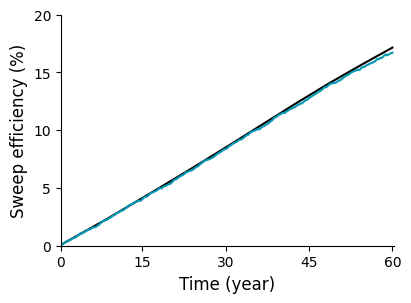

In [111]:
def compare_sweep(gt, gene):
    gt_sat = gt[:, ..., 1]
    gt_sweep = gt_sat.sum(dim=-1) / 2491
    
    gene_sat = gene[:, ..., 1]
    gene_sweep = gene_sat.sum(dim=-1) / 2491
    return gt_sweep, gene_sweep


gt_sweep, gene_sweep = compare_sweep(gt, plume)
fig, ax = plt.subplots(1, 1, figsize=(4.3, 3))
ax.plot(gt_sweep, color='k', lw=1.5)
ax.plot(gene_sweep.mean(dim=0), color='#0499b4', lw=1.5)
ax.fill_between(range(len(gene_sweep[0])), gene_sweep.mean(dim=0) - gene_sweep.std(dim=0), gene_sweep.mean(dim=0) + gene_sweep.std(dim=0), color='#0499b4', alpha=0.1, edgecolor='none')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_ylim(0, 0.2)
ax.set_xlim(0, 192)
labels = [0, 15, 30, 45, 60]
positions = [int(x * 191 / 60) for x in labels]
ax.set_xticks(ticks=positions, labels=[str(x) for x in labels])
ax.set_xlabel('Time (year)', fontsize=12)
ax.set_yticks([0.0, 0.05, 0.1, 0.15, 0.2])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*100:.0f}'))
ax.set_ylabel('Sweep efficiency (%)', fontsize=12)
plt.savefig("Egg_outputs/figs/Sweep_efficiency_plume5%.pdf", bbox_inches='tight')

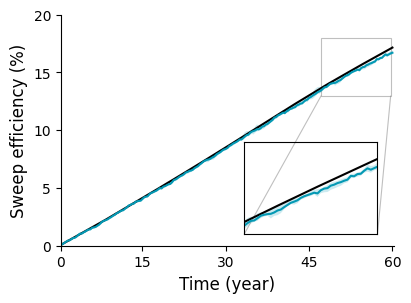

In [141]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

gt_sweep, gene_sweep = compare_sweep(gt, plume)
fig, ax = plt.subplots(1, 1, figsize=(4.3, 3))
ax.plot(gt_sweep, color='k', lw=1.5)
ax.plot(gene_sweep.mean(dim=0), color='#0499b4', lw=1.5)
ax.fill_between(range(len(gene_sweep[0])), gene_sweep.min(dim=0)[0], gene_sweep.max(dim=0)[0], color='#0499b4', alpha=0.2, edgecolor='none')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_ylim(0, 0.2)
ax.set_xlim(0, 192)
labels = [0, 15, 30, 45, 60]
positions = [int(x * 191 / 60) for x in labels]
ax.set_xticks(ticks=positions, labels=[str(x) for x in labels])
ax.set_xlabel('Time (year)', fontsize=12)
ax.set_yticks([0.0, 0.05, 0.1, 0.15, 0.2])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*100:.0f}'))
ax.set_ylabel('Sweep efficiency (%)', fontsize=12)

axins = ax.inset_axes([0.55, 0.05, 0.4, 0.4])
axins.plot(gt_sweep, color='k', lw=1.5)
axins.plot(gene_sweep.mean(dim=0), color='#0499b4', lw=1.5)
axins.fill_between(range(len(gene_sweep[0])), gene_sweep.min(dim=0)[0], gene_sweep.max(dim=0)[0], color='#0499b4', alpha=0.2, edgecolor='none')

x1, x2 = 150, 190
y1, y2 = 0.13, 0.18
axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)
axins.set_xticks([])
axins.set_yticks([])

mark_inset(ax, axins, loc1=3, loc2=4, fc="none", ec="gray", lw=0.8, alpha=0.5)

plt.savefig("Egg_outputs/figs/Sweep_efficiency_plume5%_zoomin.pdf", bbox_inches='tight')
plt.show()

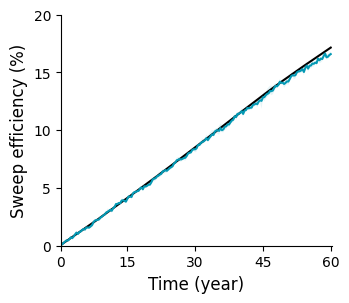

In [15]:
def compare_sweep(gt, gene):
    gt_sat = gt[:, ..., 1]
    gt_sweep = gt_sat.sum(dim=-1) / 2491
    
    gene_sat = gene[:, ..., 1]
    gene_sweep = gene_sat.sum(dim=-1) / 2491
    return gt_sweep, gene_sweep


gt_sweep, gene_sweep = compare_sweep(gt, plume10)
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3))
ax.plot(gt_sweep, color='k', lw=1.5)
ax.plot(gene_sweep.mean(dim=0), color='#0499b4', lw=1.5)
ax.fill_between(range(len(gene_sweep[0])), gene_sweep.min(dim=0)[0], gene_sweep.max(dim=0)[0], color='#0499b4', alpha=0.1, edgecolor='none')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_ylim(0, 0.2)
ax.set_xlim(0, 192)
labels = [0, 15, 30, 45, 60]
positions = [int(x * 191 / 60) for x in labels]
ax.set_xticks(ticks=positions, labels=[str(x) for x in labels])
ax.set_xlabel('Time (year)', fontsize=12)
ax.set_yticks([0.0, 0.05, 0.1, 0.15, 0.2])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*100:.0f}'))
ax.set_ylabel('Sweep efficiency (%)', fontsize=12)
plt.savefig("Egg_outputs/figs/Sweep_efficiency_plume10%.pdf", bbox_inches='tight')

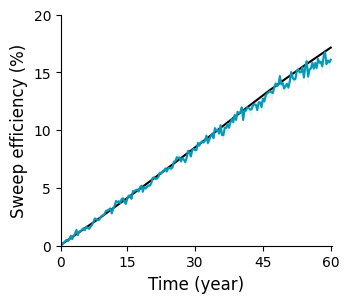

In [19]:
def compare_sweep(gt, gene):
    gt_sat = gt[:, ..., 1]
    gt_sweep = gt_sat.sum(dim=-1) / 2491
    
    gene_sat = gene[:, ..., 1]
    gene_sweep = gene_sat.sum(dim=-1) / 2491
    return gt_sweep, gene_sweep


gt_sweep, gene_sweep = compare_sweep(gt, plume20)
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3))
ax.plot(gt_sweep, color='k', lw=1.5)
ax.plot(gene_sweep.mean(dim=0), color='#0499b4', lw=1.5)
ax.fill_between(range(len(gene_sweep[0])), gene_sweep.min(dim=0)[0], gene_sweep.max(dim=0)[0], color='#0499b4', alpha=0.1, edgecolor='none')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_ylim(0, 0.2)
ax.set_xlim(0, 192)
labels = [0, 15, 30, 45, 60]
positions = [int(x * 191 / 60) for x in labels]
ax.set_xticks(ticks=positions, labels=[str(x) for x in labels])
ax.set_xlabel('Time (year)', fontsize=12)
ax.set_yticks([0.0, 0.05, 0.1, 0.15, 0.2])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*100:.0f}'))
ax.set_ylabel('Sweep efficiency (%)', fontsize=12)
plt.savefig("Egg_outputs/figs/Sweep_efficiency_plume20%.pdf", bbox_inches='tight')

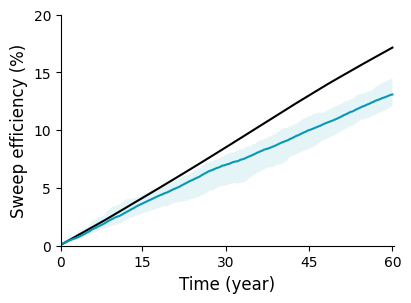

In [112]:
gt_sweep, gene_sweep = compare_sweep(gt, well_8)
fig, ax = plt.subplots(1, 1, figsize=(4.3, 3))
ax.plot(gt_sweep, color='k', lw=1.5)
ax.plot(gene_sweep.mean(dim=0), color='#0499b4', lw=1.5)
ax.fill_between(range(len(gene_sweep[0])), gene_sweep.min(dim=0)[0], gene_sweep.max(dim=0)[0], color='#0499b4', alpha=0.1, edgecolor='none')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_ylim(0, 0.2)
ax.set_xlim(0, 192)
labels = [0, 15, 30, 45, 60]
positions = [int(x * 191 / 60) for x in labels]
ax.set_xticks(ticks=positions, labels=[str(x) for x in labels])
ax.set_xlabel('Time (year)', fontsize=12)
ax.set_yticks([0.0, 0.05, 0.1, 0.15, 0.2])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*100:.0f}'))
ax.set_ylabel('Sweep efficiency (%)', fontsize=12)
plt.savefig("Egg_outputs/figs/Sweep_efficiency_well_8.pdf", bbox_inches='tight')

(10, 192) (10, 192) (10, 192)


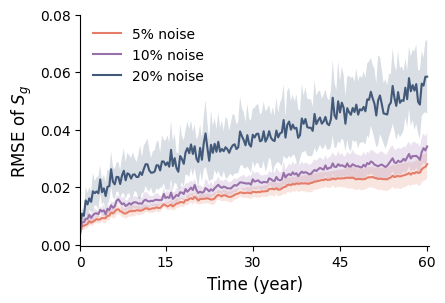

In [114]:
fig, ax = plt.subplots(1, 1, figsize=(4.5, 3))
def sat_rmse(gt, gene):
    gt_sat = gt[:, ..., 1]
    gene_sat = gene[:, ..., 1]
    rmse_list = []
    for i in range(gene_sat.shape[0]):
        for t in range(gene_sat.shape[1]):
            rmse = torch.sqrt(((gene_sat[i, t] - gt_sat[t]) ** 2).mean())
            rmse_list.append(rmse.item())
    rmse_list = np.array(rmse_list).reshape(gene_sat.shape[0], gene_sat.shape[1])
    return rmse_list
rmse_5 = sat_rmse(gt, plume)
rmse_10 = sat_rmse(gt, plume10)
rmse_20 = sat_rmse(gt, plume20)
print(rmse_5.shape, rmse_10.shape, rmse_20.shape)

ax.plot(rmse_5.mean(axis=0), color='#e57d68', lw=1.5, label='5% noise')
ax.fill_between(range(len(rmse_5[0])), rmse_5.mean(axis=0) - rmse_5.std(axis=0), rmse_5.mean(axis=0) + rmse_5.std(axis=0), color='#e57d68', alpha=0.2, edgecolor='none')
ax.plot(rmse_10.mean(axis=0), color='#9971aa', lw=1.5, label='10% noise')
ax.fill_between(range(len(rmse_10[0])), rmse_10.mean(axis=0) - rmse_10.std(axis=0), rmse_10.mean(axis=0) + rmse_10.std(axis=0), color='#9971aa', alpha=0.2, edgecolor='none')
ax.plot(rmse_20.mean(axis=0), color='#425979', lw=1.5, label='20% noise')
ax.fill_between(range(len(rmse_20[0])), rmse_20.mean(axis=0) - rmse_20.std(axis=0), rmse_20.mean(axis=0) + rmse_20.std(axis=0), color='#425979', alpha=0.2, edgecolor='none')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_xlim(0, 192)
labels = [0, 15, 30, 45, 60]
positions = [int(x * 191 / 60) for x in labels]
ax.set_xticks(ticks=positions, labels=[str(x) for x in labels])
ax.set_xlabel('Time (year)', fontsize=12)
ax.set_yticks([0.0, 0.02, 0.04, 0.06, 0.08])
ax.set_ylabel('RMSE of $S_g$', fontsize=12)
plt.legend(loc='upper left', fontsize=10, frameon=False)
plt.savefig("Egg_outputs/figs/Saturation_RMSE_noise_compare.pdf", bbox_inches='tight')
plt.show()

(2491,) (10, 2491)
761.156626506024


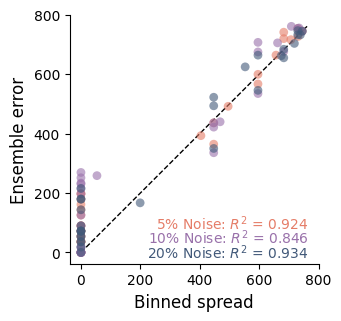

In [104]:
gt_k = gt[0, :, -1].numpy()
ensemble = plume[:, :, :, -1].mean(dim=1).numpy()  # (num_samples, 2491)
ensemble = np.where(ensemble > 800, 1500, 10)

ensemble10 = plume10[:, :, :, -1].mean(dim=1).numpy()  # (num_samples, 2491)
ensemble10 = np.where(ensemble10 > 800, 1500, 10)

ensemble20 = plume20[:, :, :, -1].mean(dim=1).numpy()  # (num_samples, 2491)
ensemble20 = np.where(ensemble20 > 800, 1500, 10)
print(gt_k.shape, ensemble.shape)

ens_mean = ensemble.mean(axis=0)       # (2491,)
ens_std = ensemble.std(axis=0)         # (2491,) spread
ens_error = np.abs(ens_mean - gt_k)      # (2491,) skill (absolute error)

ens_mean10 = ensemble10.mean(axis=0)       # (2491,)
ens_std10 = ensemble10.std(axis=0)         # (2491,) spread
ens_error10 = np.abs(ens_mean10 - gt_k)      # (2491,) skill (absolute error)

ens_mean20 = ensemble20.mean(axis=0)       # (2491,)
ens_std20 = ensemble20.std(axis=0)         # (2491,) spread
ens_error20 = np.abs(ens_mean20 - gt_k)      # (2491,) skill (absolute error)

n_bins = 30

sorted_idx = np.argsort(ens_std)
bins = np.array_split(sorted_idx, n_bins)
spread_binned = [ens_std[b].mean() for b in bins]
error_binned = [ens_error[b].mean() for b in bins]

sorted_idx10 = np.argsort(ens_std10)
bins = np.array_split(sorted_idx10, n_bins)
spread_binned10 = [ens_std10[b].mean() for b in bins]
error_binned10 = [ens_error10[b].mean() for b in bins]

sorted_idx20 = np.argsort(ens_std20)
bins = np.array_split(sorted_idx20, n_bins)
spread_binned20 = [ens_std20[b].mean() for b in bins]
error_binned20 = [ens_error20[b].mean() for b in bins]



from sklearn.metrics import r2_score
plt.figure(figsize=(3.5, 3.5))
plt.scatter(spread_binned, error_binned, color='#e57d68', s=40, zorder=3, alpha=0.6, edgecolors='none')
r2 = r2_score(spread_binned, error_binned)

plt.scatter(spread_binned10, error_binned10, color='#9971aa', s=40, zorder=3, alpha=0.6, edgecolors='none')
r2_10 = r2_score(spread_binned10, error_binned10)

plt.scatter(spread_binned20, error_binned20, color='#425979', s=40, zorder=3, alpha=0.6, edgecolors='none')
r2_20 = r2_score(spread_binned20, error_binned20)

max_val = max(max(spread_binned), max(error_binned), max(spread_binned10), max(error_binned10), max(spread_binned20), max(error_binned20))
print(max_val)
plt.plot([0, max_val], [0, max_val], 'k--', linewidth=1, label='Ideal')
plt.xlabel('Binned spread', fontsize=12)
plt.ylabel('Ensemble error', fontsize=12)
# plt.legend(fontsize=11)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_aspect('equal')
ticks = [0, 200, 400, 600, 800]
plt.xticks(ticks)
plt.yticks(ticks)
plt.text(0.96, 0.14, f'5% Noise: $R^2$ = {r2:.3f}', transform=ax.transAxes, fontsize=10, color='#e57d68', ha='right')
plt.text(0.96, 0.08, f'10% Noise: $R^2$ = {r2_10:.3f}', transform=ax.transAxes, fontsize=10, color='#9971aa', ha='right')
plt.text(0.96, 0.02, f'20% Noise: $R^2$ = {r2_20:.3f}', transform=ax.transAxes, fontsize=10, color='#425979', ha='right')
# ax.set_xlim(0, max_val * 1.05)
# ax.set_ylim(0, max_val * 1.05)
plt.tight_layout()
plt.savefig("Egg_outputs/figs/K_spread_skill.pdf", bbox_inches='tight')
plt.show()

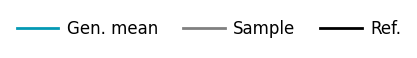

In [154]:
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='#0499b4', lw=2, ls='-', label='Gen. mean'),
    Line2D([0], [0], color='gray', lw=2, ls='-', label='Sample'),
    Line2D([0], [0], color='k', lw=2, ls='-', label='Ref.'),
]

fig, ax = plt.subplots(figsize=(3, 0.5))
ax.axis('off')

fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=3,
    frameon=False,
    handlelength=2.5,  # length of the legend lines
    handletextpad=0.5,  # space between the legend line and the text
    columnspacing=1.5,  # space between columns
    labelspacing=2,    # space between rows
    fontsize=12,
)

# plt.tight_layout()
plt.savefig("Egg_outputs/figs/LEGEND_LINE.pdf", bbox_inches='tight')
plt.show()

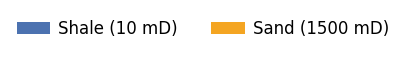

In [157]:
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor=shale_color, label="Shale (10 mD)"),
    Patch(facecolor=sand_color, label="Sand (1500 mD)")
]

fig, ax = plt.subplots(figsize=(3, 0.5))
ax.axis('off')

fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=2,
    frameon=False,
    handlelength=2,
    handletextpad=0.5,
    columnspacing=2,
    fontsize=12,
)

plt.savefig("Egg_outputs/figs/LEGEND_PATCH.pdf", bbox_inches='tight')
plt.show()

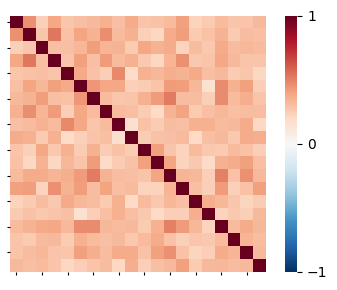

In [26]:
from sklearn.metrics.pairwise import cosine_similarity

# samples: shape (10, D)
cos_matrix = cosine_similarity(uncond[:20, :, :, -1].mean(dim=1).numpy())

plt.figure(figsize=(4, 3))
ax = sns.heatmap(cos_matrix, cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={'ticks': [-1, 0, 1]})

# plt.xlabel("Unconditional samples")
# plt.ylabel("Unconditional samples")
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.tick_params(axis='both', which='major', length=2)
plt.tight_layout()
plt.savefig("Egg_outputs/figs/[uncond]similarity.pdf", bbox_inches='tight')
plt.show()

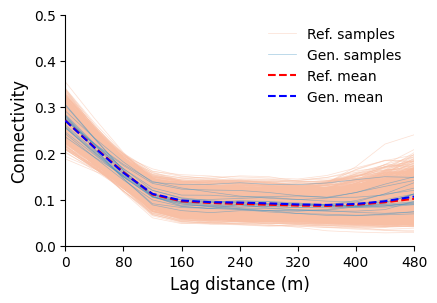

In [33]:
# uncoditional geostatistics

gt = torch.from_numpy(np.load('../../../Dataset/Egg2d_channelized_all3.npy')[:]).cpu()

masked_grid = [active_to_grid(gt[i, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan) for i in range(2000)]
gene = [active_to_grid(uncond[i, ..., -1].mean(dim=0), mesh.cell_data["flat_index"][0], nx=60, ny=60, fill_value=np.nan) for i in range(20)]

results_gt = [
    two_point_cluster_function_masked(g, max_lag=12, connectivity=8)
    for g in masked_grid
]

results_gene = [
    two_point_cluster_function_masked(g, max_lag=12, connectivity=8)
    for g in gene
]

fig, ax = plt.subplots(1, 1, figsize=(4.5, 3))

mean_gt_c2 = []
mean_c2 = []
for i in range(2000):
    lags_g, C2_g, S2_g, counts_g = results_gt[i]
    ax.plot(lags_g, C2_g, '#F8BFA4', lw=0.5, alpha=0.5, zorder=1, label='Ref. samples' if i == 0 else None)
    mean_gt_c2.append(C2_g)
for i in range(20):
    lags_g, C2_g, S2_g, counts_g = results_gene[i]
    ax.plot(lags_g, C2_g, '#4595C4', lw=0.5, alpha=0.5, zorder=1, label='Gen. samples' if i == 0 else None)
    mean_c2.append(C2_g)

ax.plot(lags_g, np.mean(mean_gt_c2, axis=0), 'red', lw=1.5, zorder=101, ls='--', label='Ref. mean')
ax.plot(lags_g, np.mean(mean_c2, axis=0), 'blue', lw=1.5, zorder=101, ls='--', label='Gen. mean')

# ax.fill_between(lags_g, np.min(mean_gt_c2, axis=0), np.max(mean_gt_c2, axis=0), color='gray', alpha=0.1, zorder=0)

ax.set_xlabel('Lag distance (m)', fontsize=12)
ax.set_ylabel('Connectivity', fontsize=12)
ax.set_ylim(0.00, 0.50)
ax.set_yticks([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
ax.set_xlim(0, 12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x*40:.0f}'))

ax.legend(loc='upper right', fontsize=10, frameon=False)


plt.savefig("Egg_outputs/figs/Uncond_K_statistics.pdf", bbox_inches='tight')
plt.show()